# Bloc B — Étude d’un Transformer causal et baseline conversationnelle Brainmaxxing

**Mini-projet 2 — Agent conversationnel | Étapes 2 et 3**

Dans cette partie, nous avons étudié le fonctionnement d'un modèle de langage causal pré-entraîné, puis nous l'avons utilisé pour construire une première version de l'agent pédagogique Brainmaxxing, **sans entraînement supplémentaire**. 
Les deux objectifs sont complémentaires : comprendre comment le modèle prédit et génère des tokens, puis vérifier son comportement sur les fiches de concepts définies dans le projet.

Les observations reposent sur `Qwen/Qwen2.5-3B-Instruct` et sur les fiches JSON situées dans `data/concepts/json/`. 
Les expériences de tokenisation et de décodage précèdent les essais de dialogue, afin de distinguer le fonctionnement du modèle de la qualité de ses évaluations pédagogiques.

## 1. Chargement du modèle et du tokenizer

Nous avons retenu **`Qwen/Qwen2.5-3B-Instruct`**, un Transformer causal instructionnel capable de traiter le français. Les poids sont chargés **une seule fois** via `load_model()` dans `src/llm/model.py` : les modules du projet réutilisent ensuite la même instance pour la baseline. Cela évite de saturer la mémoire GPU en rechargeant un modèle de 3 milliards de paramètres.

L'API attendue de Hugging Face est **`AutoTokenizer.from_pretrained`** pour la tokenisation et **`AutoModelForCausalLM.from_pretrained`** pour le modèle causal. La cellule de vérification ci-dessous affiche les types réellement instanciés et les lignes correspondantes dans le code de `src/llm/model.py`, afin de rendre le chargement **auditable** sans le répéter.

Le modèle reste **en mode évaluation**, sans mise à jour des poids dans ce bloc.

In [1]:
import sys
from pathlib import Path
import torch

root = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / "src" / "llm" / "model.py").exists()), None)
if root is None:
    raise RuntimeError("Ouvrir ce notebook depuis la racine du dépôt ou experiments/.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.llm.model import load_model
llm = load_model()
model, tokenizer, device = llm.model, llm.tokenizer, llm.device
print("Modèle : Qwen/Qwen2.5-3B-Instruct | device :", device)
print("Taille du vocabulaire :", len(tokenizer))

Chargement du modèle : Qwen/Qwen2.5-3B-Instruct
Device utilisé : cuda


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Modèle : Qwen/Qwen2.5-3B-Instruct | device : cuda
Taille du vocabulaire : 151665


### 1.1. Vérification du chargement `transformers`

Un chargement direct (hors du composant partagé) reposerait sur les deux appels suivants :

```python
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = "Qwen/Qwen2.5-3B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, device_map="auto")
model.eval()
```

**Ce bloc est illustratif et n'est pas exécuté** : le modèle est **déjà chargé** par `load_model()`. La cellule suivante inspecte l'implémentation réellement utilisée par le projet et vérifie les objets obtenus. Les deux appels ne doivent pas être effectués une seconde fois en mémoire GPU.

In [2]:
from transformers import AutoTokenizer, AutoModelForCausalLM, PreTrainedModel, PreTrainedTokenizerBase

# On contrôle les objets déjà chargés, sans allouer un second modèle de 3B paramètres.
print("Classe du tokenizer :", type(tokenizer).__name__)
print("Classe du modèle    :", type(model).__name__)
print("Identifiant modèle  :", getattr(model.config, "_name_or_path", "non indiqué"))
print("Transformer causal  :", not getattr(model.config, "is_encoder_decoder", True))
print("Mode évaluation     :", not model.training)
assert isinstance(tokenizer, PreTrainedTokenizerBase), "Le tokenizer n'est pas de type Hugging Face."
assert isinstance(model, PreTrainedModel), "Le modèle n'est pas un PreTrainedModel Hugging Face."
assert not getattr(model.config, "is_encoder_decoder", True), "Un modèle causal décodeur seul est attendu."

# Le code exact de chargement est dans le dépôt, pas dupliqué dans le notebook.
loader_path = root / "src" / "llm" / "model.py"
loader_source = loader_path.read_text(encoding="utf-8")
relevant_lines = [
    (line_num, line.rstrip())
    for line_num, line in enumerate(loader_source.splitlines(), start=1)
    if "AutoTokenizer" in line or "AutoModelForCausalLM" in line or "from_pretrained" in line
]
print("\nAppels/imports pertinents dans src/llm/model.py :")
for line_num, line in relevant_lines:
    print(f"  L{line_num}: {line.strip()}")
if not relevant_lines:
    print("Aucun appel direct visible : vérifier les éventuelles fonctions de chargement déléguées.")


Classe du tokenizer : Qwen2Tokenizer
Classe du modèle    : Qwen2ForCausalLM
Identifiant modèle  : Qwen/Qwen2.5-3B-Instruct
Transformer causal  : True
Mode évaluation     : True

Appels/imports pertinents dans src/llm/model.py :
  L4: from transformers import AutoModelForCausalLM, AutoTokenizer
  L12: tokenizer: AutoTokenizer
  L13: model: AutoModelForCausalLM
  L47: tokenizer = AutoTokenizer.from_pretrained(model_name)
  L49: model = AutoModelForCausalLM.from_pretrained(


**Observation.** Le modèle a été chargé sur **CUDA** et le tokenizer comporte **151 665 entrées** selon `len(tokenizer)`. Le chargement confirme que les expériences suivantes sont réalisées sur le modèle instructionnel retenu, sans étape d'entraînement.

## 2. Tokenisation d'une phrase

Avant de prédire quoi que ce soit, le modèle reçoit une suite d'**identifiants entiers** et non directement des mots. Le tokenizer peut découper un mot en plusieurs unités, ce qui signifie qu'un token n'est pas nécessairement un mot complet.

Nous avons pris comme entrée la phrase courte « Paris est la capitale de ». Cette phrase permet aussi d'observer facilement la prédiction du token qui suit.

In [3]:
text = "Paris est la capitale de"
encoded = tokenizer(text, return_tensors="pt")
print("IDs :", encoded["input_ids"].tolist())
print("Tokens :", tokenizer.convert_ids_to_tokens(encoded["input_ids"][0]))
print("Shape input_ids :", tuple(encoded["input_ids"].shape))

IDs : [[59604, 1788, 1187, 60410, 1574, 409]]
Tokens : ['Paris', 'Ġest', 'Ġla', 'Ġcapit', 'ale', 'Ġde']
Shape input_ids : (1, 6)


**Observation.** La phrase comporte six tokens, représentés par le tenseur de forme **`(1, 6)`**. Le mot « capitale » est notamment séparé en `Ġcapit` et `ale` : le préfixe `Ġ` signale l'espace dans cette représentation de tokenizer. Une frontière de mot ne correspond donc pas nécessairement à une frontière de token.

## 3. Prédiction du prochain token : logits, softmax et argmax

Le Transformer produit, pour chaque position de la séquence, un score pour chaque entrée de son vocabulaire de sortie. Ces scores, appelés **logits**, ne sont pas des probabilités : ils peuvent prendre des valeurs quelconques. Sur le dernier token de l'entrée, la fonction *softmax* permet de transformer les logits en une distribution :

$$P(v=j\mid \text{contexte})=\frac{\exp(z_j)}{\sum_{k}\exp(z_k)}.$$

Ici, $z_j$ désigne le logit du token candidat $j$. La somme des probabilités vaut 1, à la précision numérique près. **Argmax** retient ensuite le token de probabilité maximale ; il ne s'agit pas d'un tirage aléatoire.

In [4]:
inputs = {key: value.to(device) for key, value in encoded.items()}
with torch.no_grad():
    outputs = model(**inputs)
logits = outputs.logits
last_logits = logits[0, -1, :].float()
probs = torch.softmax(last_logits, dim=-1)
print("Shape logits complets :", tuple(logits.shape))
print("Shape dernier token :", tuple(last_logits.shape))
print("Somme des probabilités :", probs.sum().item())
vals, ids = torch.topk(probs, 8)
for idx, prob in zip(ids.tolist(), vals.tolist()):
    print(f"ID={idx:<7} token={tokenizer.decode([idx])!r:<20} prob={prob:.5f}")
print("Argmax des logits :", int(last_logits.argmax()), tokenizer.decode([last_logits.argmax().item()]))
assert torch.argmax(last_logits) == torch.argmax(probs)

Shape logits complets : (1, 6, 151936)
Shape dernier token : (151936,)
Somme des probabilités : 0.9999998807907104
ID=1187    token=' la'                prob=0.77933
ID=326     token=' l'                 prob=0.10547
ID=9625    token=' France'            prob=0.03880
ID=25025   token=' quel'              prob=0.00525
ID=320     token=' ('                 prob=0.00525
ID=549     token=' :'                 prob=0.00493
ID=7774    token=' qui'               prob=0.00493
ID=28349   token=' notre'             prob=0.00463
Argmax des logits : 1187  la


### Interprétation et lien avec les TP Transformers

La forme mesurée des logits est **`(1, 6, 151936)`** : une phrase traitée, six positions de tokens et 151 936 scores de sortie à chaque position. La dernière position a donc une forme de **`(151936,)`**. Le tokenizer annonce par ailleurs 151 665 entrées ; cette différence montre qu'il faut distinguer la taille exposée par le tokenizer et la dimension de la tête de sortie du modèle.

Pour le contexte « Paris est la capitale de », le token **« la »** est largement majoritaire avec une probabilité d'environ **77,93 %**. Les candidats « l » (10,55 %) et « France » (3,88 %) arrivent ensuite. Le modèle ne choisit donc pas immédiatement « France » : sa continuation la plus probable commence par « la », ce qui permettra ensuite de produire « France ». La somme calculée, `0.9999998807907104`, est très proche de 1 ; le léger écart provient des calculs en virgule flottante.

Ces observations correspondent aux mécanismes étudiés en TP :

- **Embeddings** : les six identifiants sont représentés par des vecteurs appris. Ils servent d'entrée aux blocs du Transformer.
- **Attention causale** : chaque position utilise les tokens précédents et elle-même, pas les tokens futurs. Qwen2.5 utilise notamment des informations de position de type RoPE dans l'attention.
- **Unembedding / tête de langage** : les représentations internes sont projetées vers les 151 936 logits observés. La softmax est appliquée à ces scores pour interpréter la prédiction.
- **Génération autorégressive** : après avoir choisi un token, on l'ajoute à la séquence et on répète le calcul pour continuer la phrase.

Le fait d'obtenir un score pour chaque position vient du traitement de toute la séquence. En génération, c'est surtout la **dernière position** qui nous intéresse.

### 3.1. Schéma du passage des tokens aux prédictions

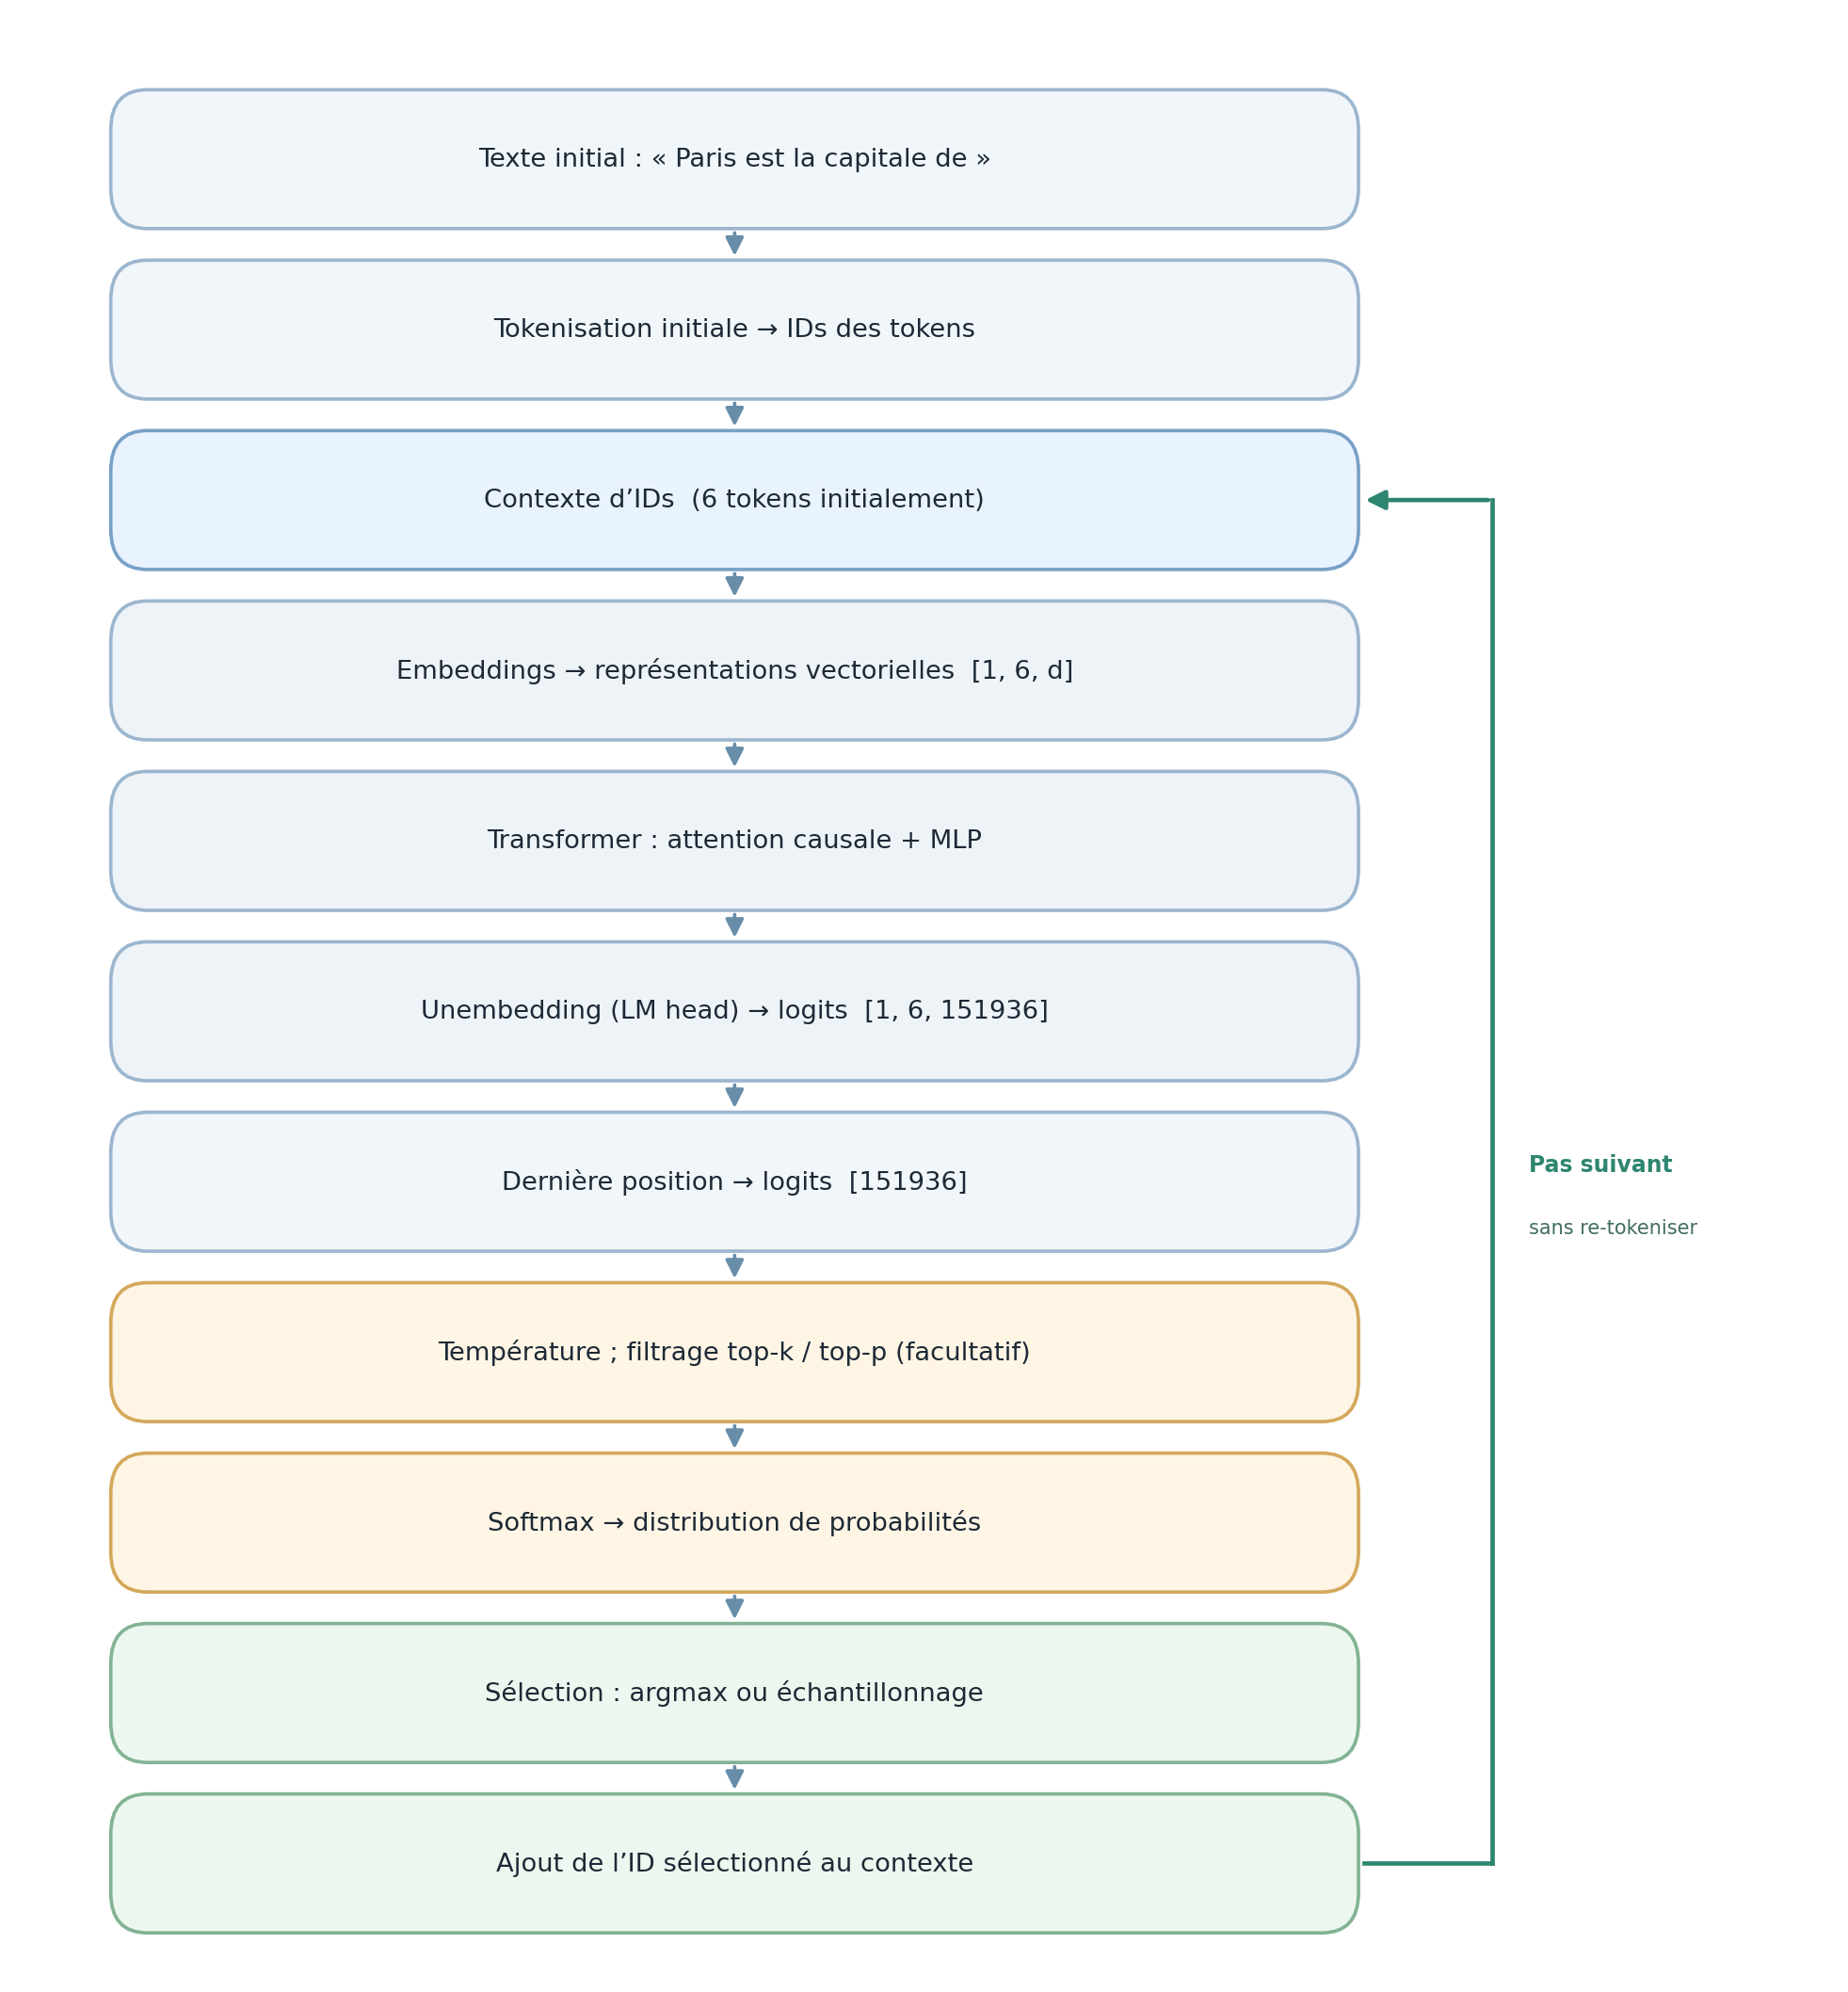

**Lecture.** Les tokens sont d'abord transformés en vecteurs d'embedding. Les blocs à **attention causale** produisent des représentations contextualisées sans voir les positions futures. La tête de langage (*unembedding*) projette ces représentations vers un logit par entrée du vocabulaire de sortie. Pour prédire **le prochain token**, on ne conserve que les logits de la **dernière position** : on peut alors appliquer la température, éventuellement restreindre les candidats avec top-k ou top-p, normaliser avec softmax et sélectionner un ID. Celui-ci est ajouté au contexte pour le pas autorégressif suivant.

*Dans l'implémentation, top-p détermine son seuil à partir des probabilités, puis les scores autorisés sont renormalisés avant le tirage. Le schéma résume les étapes conceptuelles ; le calcul de toute la séquence à chaque pas peut être optimisé par cache KV.*

## 4. Effet des stratégies de décodage

La génération ne dépend pas uniquement des paramètres appris : elle dépend aussi de la façon dont le prochain token est choisi. Nous avons comparé les mécanismes suivants sur un **même contexte**, afin de ne pas attribuer à la température ou à l'échantillonnage des différences dues au prompt :

- **Argmax (greedy)** : choisir systématiquement le token dont le logit est maximal.
- **Température** : diviser les logits par \(T\) avant la softmax. Une température inférieure à 1 renforce les choix dominants ; au-dessus de 1, la distribution devient plus répartie.
- **Top-k** : ne conserver que les \(k\) candidats les mieux classés.
- **Top-p** : garder le plus petit ensemble de candidats dont la probabilité cumulée atteint le seuil fixé, ici 0,90.

Ces opérations modifient **le décodage**, mais ne réentraînent pas le modèle.

In [5]:
from src.llm.decoding import apply_temperature, apply_top_k, apply_top_p, sample_next_token

for temperature in (0.3, 1.0, 1.5):
    distribution = torch.softmax(apply_temperature(last_logits, temperature), dim=-1)
    print(f"T={temperature}, max P={distribution.max().item():.4f}, top ID={distribution.argmax().item()}")

k_logits = apply_top_k(last_logits, 5)
p_logits = apply_top_p(last_logits, 0.90)
print("top-k=5 :", int(torch.isfinite(k_logits).sum()), "candidats conservés")
print("top-p=0.90 :", int(torch.isfinite(p_logits).sum()), "candidats conservés")

# Tirages reproductibles sur la distribution de la même position.
torch.manual_seed(123)
print("Sampling T=0.8 :", [tokenizer.decode([sample_next_token(last_logits, temperature=0.8, top_k=50, top_p=0.9).item()]) for _ in range(5)])

T=0.3, max P=0.9987, top ID=1187
T=1.0, max P=0.7793, top ID=1187
T=1.5, max P=0.3419, top ID=1187
top-k=5 : 5 candidats conservés
top-p=0.90 : 3 candidats conservés
Sampling T=0.8 : [' la', ' la', ' la', ' la', ' la']


**Observation sur les probabilités.** Le token le plus probable reste le même, mais sa probabilité passe de **99,87 %** à `T=0.3`, à **77,93 %** à `T=1`, puis à **34,19 %** à `T=1.5`. La température agit donc bien sur la dispersion, sans modifier ici le classement du meilleur token.

Avec `top-k=5`, seuls **cinq candidats** restent possibles. Avec `top-p=0.90`, seuls **trois candidats** suffisent pour atteindre le seuil dans cette distribution très concentrée. Les cinq tirages à `T=0.8` produisent tous « la » ; cela reste compatible avec un échantillonnage, car la distribution privilégie fortement ce token.

In [6]:
from src.llm.decoding import greedy_generate, generate
prompt_decodage = "Paris est la capitale de"
print("ARGMAX :", greedy_generate(model, tokenizer, prompt_decodage, device, max_new_tokens=18))
for temperature in (0.3, 0.8, 1.5):
    torch.manual_seed(42)
    answer = generate(model, tokenizer, prompt_decodage, device,
                      max_new_tokens=18, temperature=temperature, top_k=40, top_p=0.9)
    print(f"SAMPLING T={temperature} :", answer)
# Les chaînes sont limitées ici à 18 nouveaux tokens pour comparer les décodages.

ARGMAX : Paris est la capitale de la France. C'est une ville très grande. Elle est très belle. Elle a beaucoup
SAMPLING T=0.3 : Paris est la capitale de la France. C'est une ville très grande. Il y a beaucoup de monde dans la
SAMPLING T=0.8 : Paris est la capitale de la France. L'architecte Pierre Chareau a conçu plusieurs bâtiments
SAMPLING T=1.5 : Paris est la capitale de la France. Dans cette question, "de" indique-t-il quel rapport entre la


**Observation sur les textes générés.** Les quatre générations commencent par « Paris est la capitale de la France », mais elles divergent ensuite. Le décodage glouton conserve une suite très prévisible. À `T=0.3`, le texte reste proche de cette continuation ; à `T=0.8`, il bifurque vers une information annexe sur un architecte ; à `T=1.5`, il s'éloigne davantage de l'objectif initial en formulant une question sur la préposition « de ».

La température plus élevée favorise ici des continuations moins attendues, mais **une seule génération par réglage ne permet pas de mesurer statistiquement la diversité ou la qualité**. Les textes s'arrêtent parfois au milieu d'une phrase parce que chaque essai est limité à 18 nouveaux tokens.

### 4.1. Expérience contrôlée : top-k **seul** et top-p **seul**

Dans les générations précédentes, `top_k=40` et `top_p=0.90` étaient **activés simultanément**, ce qui ne permettait pas d'isoler leur rôle. Nous fixons ici **le même contexte**, **la même température** (`T=1.5`), **le même nombre de tokens générés** et **la même graine aléatoire**. Seul le filtre varie :

| Configuration | top-k | top-p | Ce qui est étudié |
|:--|--:|--:|:--|
| Échantillonnage sans filtre | désactivé | désactivé | Distribution complète |
| Top-k seul | 5 | désactivé | Ensemble fixe des 5 candidats les plus probables |
| Top-p seul | désactivé | 0,90 | Ensemble variable couvrant au moins 90 % de la masse probabiliste |

Le **nombre de candidats conservés** et leurs **probabilités après renormalisation** sont mesurés **sur le même prochain token**. La génération complète qui suit est une illustration qualitative, et non une mesure statistique de diversité.

In [7]:
from collections import Counter

# Comparaison à la même position ("Paris est la capitale de") : isoler chaque filtre.
TEMPERATURE_CONTROLE = 1.5
TOP_K_CONTROLE = 5
TOP_P_CONTROLE = 0.90
scaled_logits = apply_temperature(last_logits, TEMPERATURE_CONTROLE)

distributions_controlees = {
    "Sans filtre": scaled_logits,
    "Top-k seul (k=5)": apply_top_k(scaled_logits, TOP_K_CONTROLE),
    "Top-p seul (p=0.90)": apply_top_p(scaled_logits, TOP_P_CONTROLE),
}

for strategie, scores in distributions_controlees.items():
    distribution = torch.softmax(scores.float(), dim=-1)
    candidats = int(torch.isfinite(scores).sum().item())
    top_probs, top_ids = torch.topk(distribution, 5)
    principaux = [
        (tokenizer.decode([token_id]), round(prob, 3))
        for token_id, prob in zip(top_ids.tolist(), top_probs.tolist()) if prob > 0
    ]
    torch.manual_seed(123)
    tirages = torch.multinomial(distribution, num_samples=20, replacement=True)
    comptes = Counter(tokenizer.decode([token_id]) for token_id in tirages.tolist())
    print(f"{strategie}: {candidats} candidats ; 5 premiers = {principaux}")
    print("  20 tirages du prochain token :", dict(comptes))

# Génération autorégressive avec le générateur standard de Transformers.
# Pour cette API, top_k=0 et top_p=1.0 désactivent ces filtres.
configs = {
    "Sans filtre": {"top_k": 0, "top_p": 1.0},
    "Top-k seul (k=5)": {"top_k": TOP_K_CONTROLE, "top_p": 1.0},
    "Top-p seul (p=0.90)": {"top_k": 0, "top_p": TOP_P_CONTROLE},
}
encoded_generation = tokenizer("Paris est la capitale de", return_tensors="pt").to(device)
for strategie, filtres in configs.items():
    torch.manual_seed(42)
    with torch.inference_mode():
        tokens_generes = model.generate(
            **encoded_generation,
            do_sample=True,
            temperature=TEMPERATURE_CONTROLE,
            max_new_tokens=18,
            pad_token_id=tokenizer.eos_token_id,
            **filtres,
        )
    print(f"Génération {strategie} : {tokenizer.decode(tokens_generes[0], skip_special_tokens=True)}")


Sans filtre: 151936 candidats ; 5 premiers = [(' la', 0.342), (' l', 0.09), (' France', 0.046), (' quel', 0.012), (' (', 0.012)]
  20 tirages du prochain token : {' l': 1, ' sû': 1, ' la': 9, '\n': 1, '$\n': 1, ' France': 1, ' didn': 1, ' Nu': 1, ' –': 1, ' c': 1, 'Mont': 1, ' ': 1}
Top-k seul (k=5): 5 candidats ; 5 premiers = [(' la', 0.68), (' l', 0.179), (' France', 0.092), (' quel', 0.024), (' (', 0.024)]
  20 tirages du prochain token : {' l': 2, ' France': 1, ' la': 15, ' (': 2}
Top-p seul (p=0.90): 2334 candidats ; 5 premiers = [(' la', 0.38), (' l', 0.1), (' France', 0.051), (' quel', 0.014), (' (', 0.014)]
  20 tirages du prochain token : {' l': 1, ' _____': 1, ' la': 11, '~': 1, ' chose': 1, ' Port': 1, ' quel': 2, '\n\n': 1, ' ': 1}
Génération Sans filtre : Paris est la capitale de la Taie住房安全研究中国裁判· 上的相关坍损情形高地指头誠
Génération Top-k seul (k=5) : Paris est la capitale de la France. C'est un très beau pays.
Je suis désolé, mais il
Génération Top-p seul (p=0.90) : Paris est la ca

**Interprétation attendue, à confronter aux résultats exécutés.** Avec `top-k=5`, exactement **cinq** logits restent admissibles, quel que soit leur poids cumulé. Avec `top-p=0.90`, le **nombre de candidats dépend de la distribution** : il ne faut donc pas reprendre le résultat antérieur de *trois candidats* obtenu à `T=1.0`, car la comparaison est ici réalisée à `T=1.5`. Sans filtre, toute la distribution reste accessible (hors éventuels arrondis numériques).

Le tirage reste **aléatoire même lorsque la graine est fixée** : fixer la graine facilite la reproduction d'une expérience, sans transformer l'échantillonnage en argmax. Les trois générations peuvent produire des textes différents, mais quelques exemples ne suffisent pas à conclure qu'une stratégie est généralement plus pertinente ou plus créative. Pour le démontrer, il faudrait répéter les tirages et mesurer la diversité et la qualité sur plusieurs prompts.

## 5. Construction de la baseline conversationnelle

Après l'observation du modèle, nous avons construit une **baseline sans fine-tuning**. L'agent doit évaluer une réponse écrite à une question issue d'une fiche pédagogique, puis produire un verdict et un retour. Le résultat doit respecter le contrat partagé avec les autres blocs : `verdict`, `feedback`, `raw_response` et `valid_format`.

Le prompt système contient le rôle du tuteur, la question courante et la grille issue de `data/concepts/json/`. L'inférence utilise le **chat template du tokenizer Qwen**, qui sépare les rôles `system`, `user` et `assistant`. Le moteur conserve au maximum **trois échanges précédents complets**, en plus de la demande courante. La génération est déterministe (`do_sample=False`) avec `max_new_tokens=160`, afin de limiter les variations aléatoires et de comparer les prompts dans des conditions stables.

Deux formulations sont étudiées : **`criteria`**, qui fournit les critères de la fiche, et **`fewshot`**, qui ajoute les exemples de réponse associés aux niveaux de la grille. La différence porte sur le prompt, pas sur les poids de Qwen.

In [8]:
from src.agents.concepts import load_concept
from src.agents.inference import generate_response
from src.llm.prompts import build_pedagogical_prompt

fiche = load_concept("monty-hall")
question = fiche["questions"][0]
messages = [{"role": "user", "content": "Je garde, car il reste deux portes donc 50/50."}]
print("Question :", question["enonce"])
print("Template :", tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)[:320])
for version in ("criteria", "fewshot"):
    result = generate_response(messages, fiche, question, components=llm, prompt_version=version)
    print(version, result)
# Le parseur vérifie le format ; le classement reste celui du modèle.

Question : Tu gardes ou tu changes ? Écris ton choix et explique ton raisonnement, même s'il te paraît évident. Il n'y a pas de piège à cette question : on reviendra à ta réponse à la fin.
Template : <|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Je garde, car il reste deux portes donc 50/50.<|im_end|>
<|im_start|>assistant

criteria {'verdict': 'INCORRECT', 'feedback': "Ton raisonnement ne prend pas en compte le fait que le présentateur sait où est la voiture et qu'il a ouvert une porte vide. Cela change les probabilités.", 'raw_response': "[VERDICT: INCORRECT]\nTon raisonnement ne prend pas en compte le fait que le présentateur sait où est la voiture et qu'il a ouvert une porte vide. Cela change les probabilités.", 'valid_format': True}
fewshot {'verdict': 'PARTIEL', 'feedback': "Tu as identifié une situation finale simple, mais tu n'as pas explicitement mentionné le fait que le présentateur sait où est la voiture et

**Observation de la baseline.** Le `Template` affiché dans la cellule montre la mise en forme d'un message `user` seul : Qwen y ajoute son message système par défaut. Dans les appels réels de `generate_response()`, le moteur place au contraire **le prompt pédagogique dans un message `system`**, avant l'historique et la réponse de l'étudiant.

Sur « Je garde, car il reste deux portes donc 50/50 », les deux formats sont valides, mais les verdicts diffèrent : **`criteria` → `INCORRECT`** et **`fewshot` → `PARTIEL`**. La fiche `monty-hall_q1` considère pourtant le raisonnement « 50/50 » comme une intuition partielle recevable à ce stade du cours. Le few-shot suit donc mieux la grille **sur cet exemple précis**. Son feedback fournit encore une indication assez explicite sur le rôle du présentateur, ce qui montre que la qualité pédagogique ne se résume pas au verdict.

### Comparaison complémentaire des prompts sur neuf cas

Nous avons également comparé les deux variantes sur le jeu de développement, avec le script `scripts/compare_prompts.py`. Les entrées et le modèle sont identiques pour les deux stratégies ; seule la formulation du prompt change.

| Indicateur | `criteria` | `fewshot` |
|:--|--:|--:|
| Verdicts et formats conformes | **4 / 9** | **6 / 9** |
| Exactitude sur le jeu de développement | **44,44 %** | **66,67 %** |
| Sorties au format valide | **8 / 9** | **8 / 9** |

Le premier essai réalisé sur seulement deux réponses donnait l'ordre inverse (**1/2 pour `criteria`, 0/2 pour `fewshot`**). L'élargissement à neuf observations montre que la conclusion est sensible à la composition du petit échantillon. Le résultat du test de refus est notamment **mal formaté avec les deux prompts**. Nous avons conservé `fewshot` comme configuration de référence pour ces observations, sans confondre ce jeu de développement avec l'évaluation finale.

## 6. Vérification d'un dialogue sur plusieurs tours

Pour observer la prise en compte du contexte, nous avons utilisé la deuxième question de Monty Hall. La première réponse de l'étudiant donne correctement les probabilités, mais sans les expliquer : le modèle attribue `PARTIEL`. Lors du tour suivant, l'étudiant complète son raisonnement en précisant le rôle du présentateur et le lien avec le cas à trois portes. Le modèle reçoit alors la première réponse, son feedback et la nouvelle réponse.

L'expérience vérifie que la génération fonctionne sur une conversation de plusieurs messages. Elle ne suffit pas, à elle seule, à isoler l'effet de l'historique : la deuxième réponse est également plus complète que la première.

In [9]:
q2 = fiche["questions"][1]
history = [{"role": "user", "content": "Je change, mais la porte 1 a 1/100 et la 74 a 99/100."}]
result1 = generate_response(history, fiche, q2, components=llm)
history.append({"role": "assistant", "content": result1["raw_response"]})
history.append({"role": "user", "content": "Je complète : le présentateur sait où est la voiture et a ouvert 98 portes perdantes, donc les 99/100 restent sur la 74. C'est pareil qu'à 3 portes."})
result2 = generate_response(history, fiche, q2, components=llm)
print("Tour 1 :", result1)
print("Tour 2 :", result2)
# Les deux verdicts sont enregistrés tels que produits par la baseline.

Tour 1 : {'verdict': 'PARTIEL', 'feedback': 'Tu as bien noté les nombres, mais il manque une explication sur leur origine.', 'raw_response': '[VERDICT: PARTIEL]\nTu as bien noté les nombres, mais il manque une explication sur leur origine.', 'valid_format': True}
Tour 2 : {'verdict': 'PARFAIT', 'feedback': 'Ton raisonnement est clair et cohérent. Tu as bien compris que le présentateur, connaissant la position de la voiture, a concentré les chances sur la porte restante.', 'raw_response': '[VERDICT: PARFAIT]\nTon raisonnement est clair et cohérent. Tu as bien compris que le présentateur, connaissant la position de la voiture, a concentré les chances sur la porte restante.', 'valid_format': True}


**Observation multi-tours.** Le verdict passe de **`PARTIEL`** au premier tour à **`PARFAIT`** au second, avec des formats valides dans les deux cas. Le premier feedback souligne l'absence d'explication des probabilités ; le second reconnaît le rôle du présentateur et le transfert de probabilité vers la porte 74.

Le résultat correspond à la progression attendue sur cette question. Il illustre le fonctionnement d'un dialogue avec historique, mais ne prouve pas à lui seul que Qwen a effectivement utilisé le tour précédent, puisque le deuxième message apporte déjà de nouveaux éléments explicatifs.

## 7. Bilan des expériences

L'observation du modèle met en évidence le cheminement **identifiants de tokens → logits → distribution softmax → sélection → génération**. Sur notre exemple, le modèle prédit « la » avec environ 77,93 % de probabilité après « Paris est la capitale de ». La température modifie nettement la concentration de la distribution, tandis que top-k et top-p restreignent l'ensemble des candidats.

La baseline démontre qu'un Transformer instructionnel peut être utilisé **sans entraînement** pour évaluer des réponses à partir de fiches structurées. Les essais mettent toutefois en évidence une différence essentielle entre produire un texte bien formé et appliquer correctement une grille pédagogique. Dans l'exemple de Monty Hall Q1, `criteria` renvoie `INCORRECT` pour le raisonnement « 50/50 », tandis que `fewshot` renvoie `PARTIEL`, conformément à la fiche.

Sur **neuf cas de développement**, le prompt few-shot obtient **6 verdicts conformes sur 9 (66,67 %)**, contre **4 sur 9 (44,44 %)** pour le prompt `criteria`. Les deux atteignent **8 formats valides sur 9 (88,89 %)**. La variante few-shot est donc la référence retenue **pour ce jeu de développement**, et ses réponses ont été sauvegardées dans `experiments/results/baseline_reference_dev.jsonl` par le script de comparaison.

Ces résultats restent exploratoires : l'échantillon est réduit et les exemples étalons présents dans les fiches participent au prompt few-shot. Les erreurs constatées concernent notamment la frontière entre `PARTIEL` et `INCORRECT` et le format des refus. La comparaison ne démontre donc pas une amélioration générale du modèle, mais fournit un **point de référence explicite** pour évaluer ensuite l'effet de l'adaptation LoRA sur un jeu de test indépendant.